# Extended benchmark algorithm comparison

This notebook compares the scalable methods **Greedy, Heuristic, Uniform, and Random** on one-dimensional and two-dimensional datasets generated from unfiltered random field draws. Exhaustive is excluded because enumerating all allocations and adaptive trees is intended only for the compact benchmark.

Greedy allocates each sensor where it gives the largest average pairwise error reduction at a location and then builds a local minimum-$P_{ijmn}$ tree. Heuristic improves a near-uniform allocation and uses exact $P/Q$ branch probabilities to score partial and complete trees during beam search. Uniform uses a near-uniform allocation and a seeded random pair-location tree. Random uses both a seeded random allocation and tree. Every completed tree is evaluated with the full $P/Q$ branch model under equal field priors.

In [4]:
# Resolve the project whether Jupyter starts here or from the repository root.
import importlib
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working = Path.cwd().resolve()
PROJECT = working / "problem-2-min-error-seq" if (working / "problem-2-min-error-seq").is_dir() else working
SOURCE = PROJECT / "src"
if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

_analysis_module = importlib.reload(importlib.import_module("analysis"))
run_analysis = _analysis_module.run_analysis
_figures_module = importlib.reload(importlib.import_module("figures"))
save_figures = _figures_module.save_figures
summary_markdown = _figures_module.summary_markdown

## Experimental settings

`test` mode selects **180 cases per spatial dimension** and covers every $(K,M)$ pair for $K\in\{3,\ldots,10\}$ and $M\in\{2,\ldots,10\}$. Each pair contributes two or three cases, and each field family contributes 60 cases. `full` mode uses all 2,160 cases in each dimension.

The time limit applies independently to each method-budget evaluation, and checkpoint reuse supports interrupted runs. Progress is printed after every completed case, separately for each dataset.

In [5]:
# Use "full" for the complete study after confirming the test run.
RUN_MODE = "test"
RESUME = True
TIME_LIMIT_SECONDS = 30.0

# These controls apply only to the heuristic method.
BEAM_WIDTH = 3
MAX_ITERATIONS = 30

# This notebook is intentionally tied to the extended datasets.
STUDY = "extended"

## Run the matched comparison

Greedy, Heuristic, Uniform, and Random are evaluated on identical selected case-budget combinations. Results are checkpointed after every method-budget evaluation, and aggregation uses only combinations completed by all four methods.

In [6]:
# Run or resume the extended comparison with the settings above.
import importlib
run_analysis = importlib.reload(importlib.import_module("analysis")).run_analysis
analysis = run_analysis(
    project=PROJECT,
    study=STUDY,
    mode=RUN_MODE,
    resume=RESUME,
    exact_k_max=4,  # Accepted by the shared runner; Exhaustive is not used here.
    time_limit=TIME_LIMIT_SECONDS,
    beam_width=BEAM_WIDTH,
    max_iterations=MAX_ITERATIONS,
)

# Confirm that this notebook used both extended datasets and the four scalable methods.
expected_datasets = {"benchmark_1d", "benchmark_2d"}
expected_methods = {"Greedy", "Heuristic", "Uniform", "Random"}
observed_datasets = {row["dataset"] for row in analysis["rows"]}
observed_methods = {row["method"] for row in analysis["rows"]}
assert observed_datasets == expected_datasets
assert observed_methods == expected_methods
expected_k = set(range(3, 11))
expected_m = set(range(2, 11))
assert {int(row["K"]) for row in analysis["rows"]} == expected_k
assert {int(row["M"]) for row in analysis["rows"]} == expected_m
assert {(int(row["K"]), int(row["M"])) for row in analysis["rows"]} == {(K, M) for K in expected_k for M in expected_m}

case_counts = {
    dimension: len({
        (row["dataset"], row["case"])
        for row in analysis["rows"]
        if int(row["dimension"]) == dimension
    })
    for dimension in (1, 2)
}
if RUN_MODE == "test":
    assert min(case_counts.values()) >= 180

print("Verified datasets:", sorted(observed_datasets))
print("Verified methods:", sorted(observed_methods))
print("Unique cases by dimension:", case_counts)
print("Results directory:", analysis["output"])

extended/test: 360 cases, methods: Greedy, Heuristic, Uniform, Random
benchmark_1d: completed case 1/180 (gaussian, K=3, M=2)
benchmark_1d: completed case 2/180 (quadratic, K=3, M=2)
benchmark_1d: completed case 3/180 (sinusoidal, K=3, M=2)
benchmark_1d: completed case 4/180 (quadratic, K=3, M=3)
benchmark_1d: completed case 5/180 (sinusoidal, K=3, M=3)
benchmark_1d: completed case 6/180 (gaussian, K=3, M=3)
benchmark_1d: completed case 7/180 (sinusoidal, K=3, M=4)
benchmark_1d: completed case 8/180 (gaussian, K=3, M=4)
benchmark_1d: completed case 9/180 (quadratic, K=3, M=4)
benchmark_1d: completed case 10/180 (gaussian, K=3, M=5)
benchmark_1d: completed case 11/180 (quadratic, K=3, M=5)
benchmark_1d: completed case 12/180 (sinusoidal, K=3, M=5)
benchmark_1d: completed case 13/180 (quadratic, K=3, M=6)
benchmark_1d: completed case 14/180 (sinusoidal, K=3, M=6)
benchmark_1d: completed case 15/180 (gaussian, K=3, M=6)
benchmark_1d: completed case 16/180 (sinusoidal, K=3, M=7)
benchmark_

## Completion and matched summary

The completion counts are shown before aggregation. The summary table reports matched sample sizes, mean budget fraction, mean error probability, and mean runtime.

In [7]:
# Report method completion before displaying aggregate values.
from collections import Counter

completion = Counter((row["method"], row["status"]) for row in analysis["rows"])
print("Method-status counts:", completion)
display(Markdown(summary_markdown(analysis["summary"])))

Method-status counts: Counter({('Greedy', 'ok'): 1433, ('Heuristic', 'ok'): 1433, ('Uniform', 'ok'): 1433, ('Random', 'ok'): 1433})


| Dimension | Budget | Method | Cases | Mean Error Probability | Mean Time (s) | Mean Gap |
|---|---:|---|---:|---:|---:|---:|
| One-dimensional | 1 | Greedy | 180 | 0.45701 | 0.0089 | — |
| One-dimensional | 1 | Heuristic | 180 | 0.27884 | 0.5806 | — |
| One-dimensional | 1 | Random | 180 | 0.68130 | 0.0051 | — |
| One-dimensional | 1 | Uniform | 180 | 0.67658 | 0.0051 | — |
| One-dimensional | 2 | Greedy | 180 | 0.32611 | 0.0105 | — |
| One-dimensional | 2 | Heuristic | 180 | 0.11271 | 0.6021 | — |
| One-dimensional | 2 | Random | 180 | 0.59316 | 0.0051 | — |
| One-dimensional | 2 | Uniform | 180 | 0.57126 | 0.0052 | — |
| One-dimensional | 3 | Greedy | 178 | 0.23632 | 0.0123 | — |
| One-dimensional | 3 | Heuristic | 178 | 0.04215 | 0.6261 | — |
| One-dimensional | 3 | Random | 178 | 0.51578 | 0.0053 | — |
| One-dimensional | 3 | Uniform | 178 | 0.49116 | 0.0053 | — |
| One-dimensional | 4 | Greedy | 178 | 0.17798 | 0.0140 | — |
| One-dimensional | 4 | Heuristic | 178 | 0.01916 | 1.2106 | — |
| One-dimensional | 4 | Random | 178 | 0.46175 | 0.0053 | — |
| One-dimensional | 4 | Uniform | 178 | 0.43788 | 0.0053 | — |
| Two-dimensional | 1 | Greedy | 180 | 0.45038 | 0.0087 | — |
| Two-dimensional | 1 | Heuristic | 180 | 0.30485 | 0.8275 | — |
| Two-dimensional | 1 | Random | 180 | 0.69735 | 0.0050 | — |
| Two-dimensional | 1 | Uniform | 180 | 0.69131 | 0.0050 | — |
| Two-dimensional | 2 | Greedy | 180 | 0.32692 | 0.0103 | — |
| Two-dimensional | 2 | Heuristic | 180 | 0.14423 | 0.7809 | — |
| Two-dimensional | 2 | Random | 180 | 0.62208 | 0.0051 | — |
| Two-dimensional | 2 | Uniform | 180 | 0.61716 | 0.0051 | — |
| Two-dimensional | 3 | Greedy | 179 | 0.23846 | 0.0121 | — |
| Two-dimensional | 3 | Heuristic | 179 | 0.06531 | 0.7078 | — |
| Two-dimensional | 3 | Random | 179 | 0.55302 | 0.0051 | — |
| Two-dimensional | 3 | Uniform | 179 | 0.53941 | 0.0051 | — |
| Two-dimensional | 4 | Greedy | 178 | 0.18481 | 0.0136 | — |
| Two-dimensional | 4 | Heuristic | 178 | 0.03777 | 0.7140 | — |
| Two-dimensional | 4 | Random | 178 | 0.52422 | 0.0052 | — |
| Two-dimensional | 4 | Uniform | 178 | 0.49139 | 0.0052 | — |

## Comparison figures

The figures show **mean error probability versus mean budget fraction**, exact Greedy-versus-Heuristic allocation agreement as $K$ grows, mean runtime by $K$, and mean error by field family. The allocation figure has separate one-dimensional and two-dimensional panels, with one Greedy–Heuristic line in each panel. Runtime is shown as method lines versus $K$ with 95% confidence intervals in separate one-dimensional and two-dimensional panels. Field-family results use grouped mean bars with 95% confidence intervals. Total-budget agreement is omitted because every method receives the same fixed $N$. All figures use the matched samples summarized above.

### Error Probability

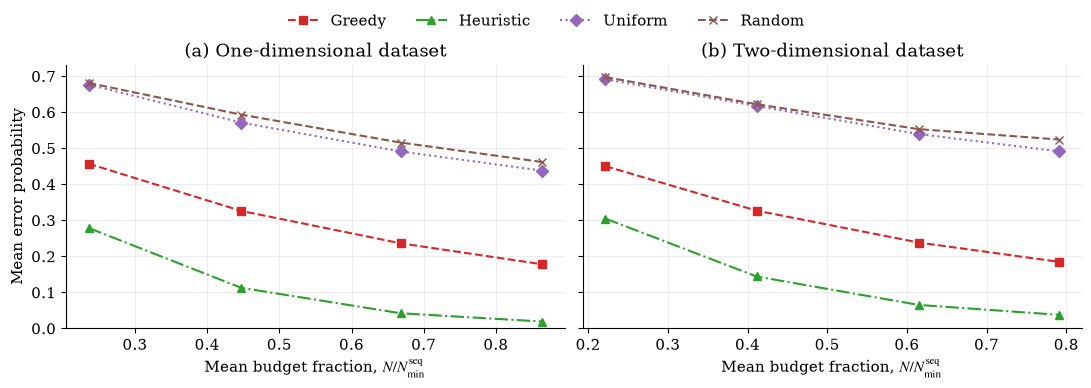

### Allocation Match

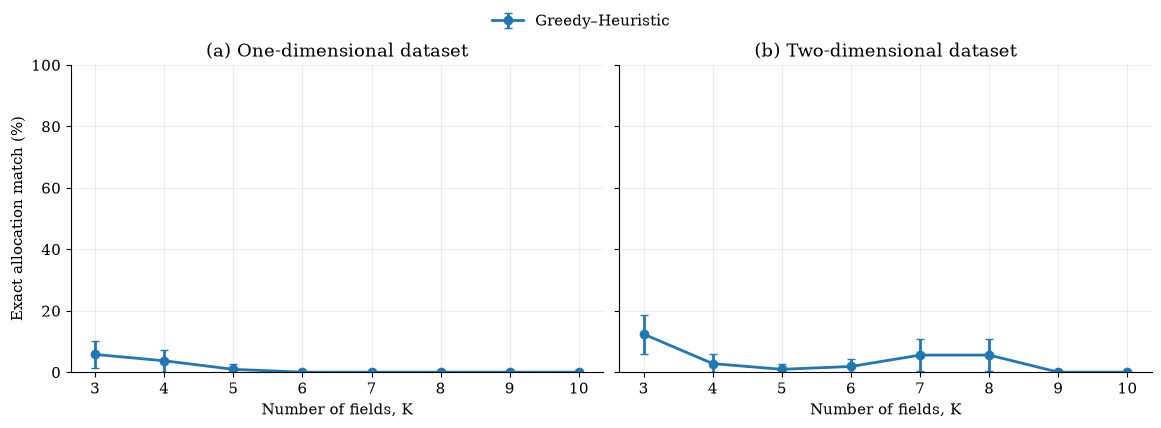

### Runtime By K

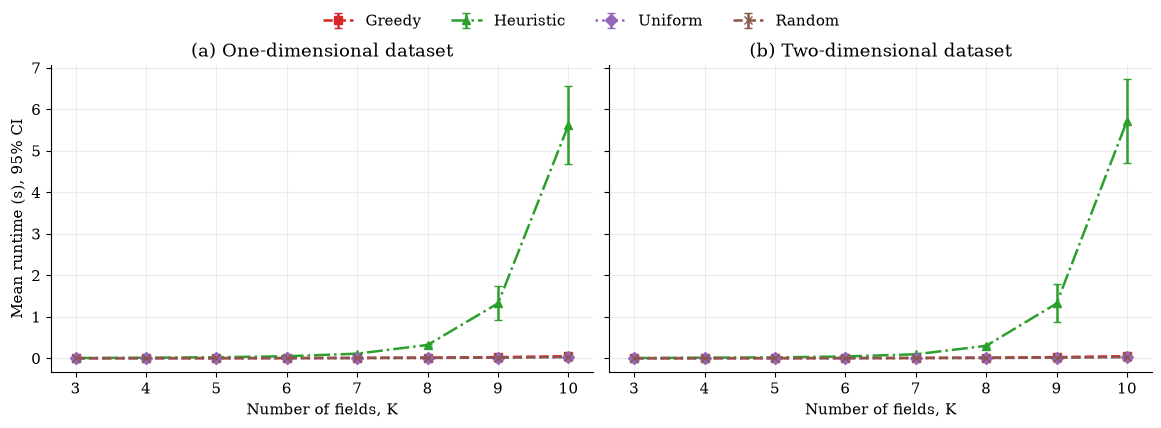

### Error By Field Family

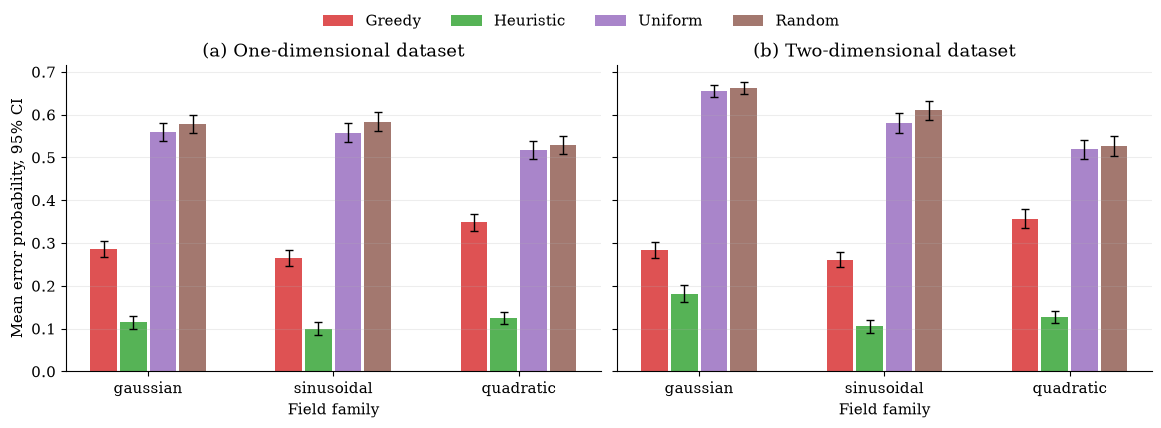

In [8]:
# Save publication-quality PDF and PNG versions, then display each figure.
save_figures = importlib.reload(importlib.import_module("figures")).save_figures
if not analysis["summary"]:
    raise RuntimeError("No matched completed cases are available for plotting")

figures = save_figures(
    analysis["summary"],
    analysis["rows"],
    analysis["output"],
)
for name, figure in figures.items():
    display(Markdown(f"### {name.replace('_', ' ').title()}"))
    display(figure)
    plt.close(figure)